In [1]:
import os
import sys
import platform
import subprocess
import psutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")

os.makedirs("data", exist_ok=True)
os.makedirs("figures", exist_ok=True)

c_exe = "src/matmul_c.exe" if sys.platform == "win32" else "./src/matmul_c"
c_cmd = ["gcc", "-O2", "src/matmul.c", "-o", c_exe]
if sys.platform == "win32":
    c_cmd.append("-lpsapi")
else:
    c_cmd.append("-lm")

subprocess.run(c_cmd, check=True)
subprocess.run(["javac", "src/MatMul.java"], check=True)

env_info = {
    "OS": f"{platform.system()} {platform.release()}",
    "Processor": platform.processor(),
    "Physical_Cores": psutil.cpu_count(logical=False),
    "Logical_Processors": psutil.cpu_count(logical=True),
    "RAM_GB": round(psutil.virtual_memory().total / (1024**3), 2),
    "Python_Version": platform.python_version(),
    "GCC_Version": subprocess.check_output(["gcc", "--version"]).decode().splitlines()[0],
    "Java_Version": subprocess.check_output(["java", "-version"], stderr=subprocess.STDOUT).decode().splitlines()[0]
}
pd.DataFrame([env_info])

,OS,Processor,Physical_Cores,Logical_Processors,RAM_GB,Python_Version,GCC_Version,Java_Version
0,Windows 11,"Intel64 Family 6 Model 170 Stepping 4, Genuine...",16,22,15.37,3.14.6,"gcc (MinGW-W64 x86_64-ucrt-posix-seh, built by...","openjdk version ""17.0.20.1"" 2026-08-18"


In [2]:
def generate_reference_matrix(n, seed):
    mat = np.zeros((n, n), dtype=np.float64)
    state = seed & 0xFFFFFFFFFFFFFFFF
    for i in range(n):
        for j in range(n):
            state = (state * 6364136223846793005 + 1442695040888963407) & 0xFFFFFFFFFFFFFFFF
            mat[i, j] = (state >> 11) * (1.0 / 9007199254740992.0)
    return mat

n_val = 16
seed_val = 42
A_ref = generate_reference_matrix(n_val, seed_val)
B_ref = generate_reference_matrix(n_val, seed_val + 1)
C_ref = np.matmul(A_ref, B_ref)

commands = {
    "Python": [sys.executable, "src/matmul.py"],
    "Java": ["java", "-cp", "src", "MatMul"],
    "C": [c_exe]
}

validation_rows = []
rtol = 1e-12
atol = 1e-12

for lang, base_cmd in commands.items():
    out_id = subprocess.check_output(base_cmd + ["identity", str(n_val), "0", "1", str(seed_val)]).decode().strip().split(",")
    out_zero = subprocess.check_output(base_cmd + ["zero", str(n_val), "0", "1", str(seed_val)]).decode().strip().split(",")
    out_dump = subprocess.check_output(base_cmd + ["dump", str(n_val), "0", "1", str(seed_val)]).decode().strip().split(",")
    C_lang = np.array([float(x) for x in out_dump], dtype=np.float64).reshape((n_val, n_val))
    max_abs_err = float(np.max(np.abs(C_lang - C_ref)))
    passed = bool(np.allclose(C_lang, C_ref, rtol=rtol, atol=atol))
    validation_rows.append({
        "Language": lang,
        "N": n_val,
        "Identity_Max_Error": float(out_id[2]),
        "Zero_Max_Error": float(out_zero[2]),
        "Ref_Max_Abs_Error": max_abs_err,
        "Passed_AllClose": passed
    })

pd.DataFrame(validation_rows)

,Language,N,Identity_Max_Error,Zero_Max_Error,Ref_Max_Abs_Error,Passed_AllClose
0,Python,16,0.0,0.0,1.776357e-15,True
1,Java,16,0.0,0.0,1.776357e-15,True
2,C,16,0.0,0.0,1.776357e-15,True


In [3]:
sizes = [10, 50, 100, 200, 300, 500, 800, 1000]
warmup_runs = 2
measured_reps = 5
seed_bench = 12345
max_runtime_budget_s = 120.0

raw_rows = []
status_rows = []

for lang, base_cmd in commands.items():
    lang_timed_out = False
    for n in sizes:
        if lang_timed_out:
            status_rows.append({"Language": lang, "N": n, "Status": "SKIPPED_AFTER_TIMEOUT"})
            continue
        cmd = base_cmd + ["benchmark", str(n), str(warmup_runs), str(measured_reps), str(seed_bench)]
        try:
            proc = subprocess.run(cmd, capture_output=True, text=True, timeout=max_runtime_budget_s, check=True)
            lines = [line.strip() for line in proc.stdout.splitlines() if line.strip()]
            for line in lines:
                parts = line.split(",")
                raw_rows.append({
                    "language": parts[0],
                    "n": int(parts[1]),
                    "numeric_type": parts[2],
                    "repetition": int(parts[3]),
                    "time_s": float(parts[4]),
                    "memory_kb": float(parts[5]),
                    "checksum": float(parts[6]),
                    "threads": int(parts[7])
                })
            status_rows.append({"Language": lang, "N": n, "Status": "COMPLETED"})
        except subprocess.TimeoutExpired:
            status_rows.append({"Language": lang, "N": n, "Status": f"TIMEOUT_EXCEEDED_{max_runtime_budget_s}S"})
            lang_timed_out = True
        except subprocess.CalledProcessError as e:
            status_rows.append({"Language": lang, "N": n, "Status": f"ERROR_CODE_{e.returncode}"})
            lang_timed_out = True

df_raw = pd.DataFrame(raw_rows)
df_raw.to_csv("data/raw_measurements.csv", index=False)

df_status = pd.DataFrame(status_rows)
df_status.to_csv("data/execution_limits.csv", index=False)
df_status

,Language,N,Status
0,Python,10,COMPLETED
1,Python,50,COMPLETED
2,Python,100,COMPLETED
3,Python,200,COMPLETED
4,Python,300,COMPLETED
5,Python,500,COMPLETED
6,Python,800,TIMEOUT_EXCEEDED_120.0S
7,Python,1000,SKIPPED_AFTER_TIMEOUT
8,Java,10,COMPLETED
9,Java,50,COMPLETED


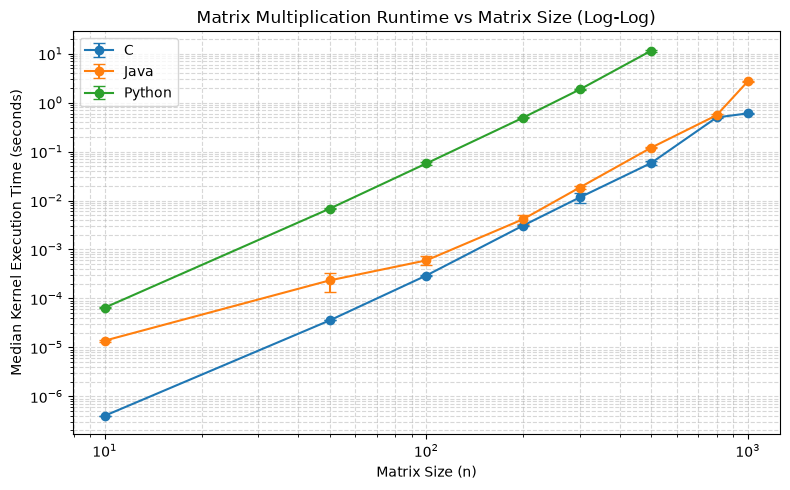

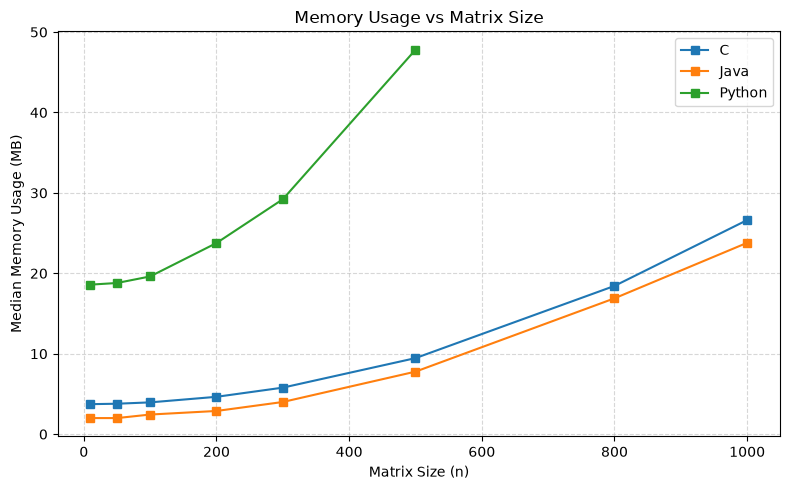

,language,n,numeric_type,threads,repetitions,median_time_s,iqr_time_s,median_memory_kb,iqr_memory_kb,checksum
0,C,10,float64,1,5,4.000000e-07,0.000000e+00,3820.00,0.0,2.709217e+02
1,C,50,float64,1,5,3.540000e-05,0.000000e+00,3876.00,0.0,3.198779e+04
2,C,100,float64,1,5,2.936000e-04,8.000000e-07,4048.00,0.0,2.539973e+05
3,C,200,float64,1,5,3.078600e-03,6.230000e-05,4756.00,0.0,2.008463e+06
4,C,300,float64,1,5,1.155340e-02,2.492200e-03,5924.00,0.0,6.754609e+06
5,C,500,float64,1,5,5.828140e-02,6.025900e-03,9684.00,0.0,3.123090e+07
6,C,800,float64,1,5,4.982638e-01,6.541800e-03,18876.00,0.0,1.279030e+08
7,C,1000,float64,1,5,6.037615e-01,6.238000e-03,27260.00,0.0,2.499376e+08
8,Java,10,float64,1,5,1.370000e-05,7.000000e-07,2048.00,0.0,2.709217e+02
9,Java,50,float64,1,5,2.329000e-04,1.007000e-04,2048.00,0.0,3.198779e+04


In [4]:
def iqr(series):
    return float(np.percentile(series, 75) - np.percentile(series, 25))

summary_df = df_raw.groupby(["language", "n", "numeric_type", "threads"], as_index=False).agg(
    repetitions=("time_s", "count"),
    median_time_s=("time_s", "median"),
    iqr_time_s=("time_s", iqr),
    median_memory_kb=("memory_kb", "median"),
    iqr_memory_kb=("memory_kb", iqr),
    checksum=("checksum", "first")
)

summary_df.to_csv("data/summary_results.csv", index=False)

plt.figure(figsize=(8, 5))
for lang in summary_df["language"].unique():
    sub = summary_df[summary_df["language"] == lang]
    plt.errorbar(sub["n"], sub["median_time_s"], yerr=sub["iqr_time_s"], marker="o", capsize=4, label=lang)
plt.xscale("log")
plt.yscale("log")
plt.xlabel("Matrix Size (n)")
plt.ylabel("Median Kernel Execution Time (seconds)")
plt.title("Matrix Multiplication Runtime vs Matrix Size (Log-Log)")
plt.legend()
plt.grid(True, which="both", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.savefig("figures/runtime_comparison.png", dpi=300)
plt.show()

plt.figure(figsize=(8, 5))
for lang in summary_df["language"].unique():
    sub = summary_df[summary_df["language"] == lang]
    plt.plot(sub["n"], sub["median_memory_kb"] / 1024.0, marker="s", label=lang)
plt.xlabel("Matrix Size (n)")
plt.ylabel("Median Memory Usage (MB)")
plt.title("Memory Usage vs Matrix Size")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.savefig("figures/memory_comparison.png", dpi=300)
plt.show()

summary_df